# Supplementary Fig S8 · End-to-end query time on several cores

End-to-end time per complete query (query logarithms + search; solid) and the query logarithms alone (dashed: the
whole-matrix eigendecomposition; Spindle's block logarithms) of the whole-matrix scan and Spindle against the number
of physical cores, one panel per dataset, on one y-axis: both approach a floor as cores are added (R11,
`experiments/common/parallel_timing.py`). Whatever can split across cores does (Spindle's block logarithms over niches
and blocks, Spindle's search over niches, the whole-matrix scan over rows, the whole-matrix eigendecomposition on T BLAS
threads), each equal bit for bit to its single-thread counterpart. Every step at its best core count up to T ("at most
T cores": per dataset and seed, the running minimum over T' ≤ T of the step's median; `parallel_timing.summary`), the
same rule for both methods. Mean ± s.d. over seeds 0–4 (first 200 held-out queries). T = 1 repeats R4's single-thread
protocol (Fig 2B). Raw medians at each T: `results/parallel/seeds.csv`.
(5 Nov: only the whole-matrix scan and Spindle, end to end and their query logarithms (dashed, 5 Nov); the speed-up panel, Spindle-naive and the query-logarithm
lines of the 4 Nov draft are dropped; draft in `_backups/`.)

**Run first:** `R11_parallel` (`results/parallel/timing.csv`).
Writes `figures/figS8_parallel/panels/{<dataset>,legend}.{pdf,png}` and `figures/figS8_parallel/figS8_parallel.{pdf,png}`.


In [1]:
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "datasets.yaml").exists())
sys.path.insert(0, str(ROOT / "experiments" / "common"))
import pandas as pd
from matplotlib.lines import Line2D
from matplotlib.ticker import FixedLocator, NullLocator

import parallel_timing as pt
import style as ps

FIG = "figS8_parallel"
tm = pd.read_csv(ROOT / "results" / "parallel" / "timing.csv")
_, summ = pt.summary(tm)
KEYS = [k for k in ps.DATASET_ORDER if k in set(summ.key)]
S = {k: summ[summ.key == k].sort_values("threads") for k in KEYS}
CORES = sorted(int(c) for c in summ.threads.unique())
# (end-to-end column, query-logarithm column, tier, marker, label)
METHODS = [("e2e_whole_best_ms", "qlog_whole_best_ms", "whole", "s", "Whole-matrix scan"),
           ("e2e_spindle_best_ms", "qlog_block_best_ms", "spindle", "D", "Spindle")]
YLIM = (0.3, 800.0)
print(KEYS, "| cores", CORES, "|", sorted(set(tm.tag)))
print(summ[summ.threads.isin([1, CORES[-1]])].pivot(index="key", columns="threads",
      values=["e2e_whole_best_ms", "e2e_spindle_best_ms"]).round(2))

NCOL, W_P, H_P, LEG_H = 4, 45.0, 42.0, 7.0
LEFT, BOTTOM, RIGHT, TOP = 10.0, 8.5, 1.5, 1.5  # mm inside a panel; y labels on the first column, x on the last row

['skin_melanoma', 'kidney_nondiseased', 'breast_cancer', 'lung_cancer', 'pancreatic_cancer', 'lymph_node', 'lymph_node_5k', 'brain_cancer'] | cores [1, 2, 4, 8, 16, 32, 64] | ['method-v2']
                   e2e_whole_best_ms        e2e_spindle_best_ms      
threads                           1      64                  1     64
key                                                                  
brain_cancer                  456.59  31.65               28.65  1.82
breast_cancer                  29.40   6.26                4.06  0.56
kidney_nondiseased             22.71   7.48                2.67  0.46
lung_cancer                    38.38   8.82                5.11  0.76
lymph_node                     50.37  10.99                8.00  0.81
lymph_node_5k                 125.69  20.09               24.23  1.61
pancreatic_cancer              87.73  15.63                6.46  0.72
skin_melanoma                  24.87   7.56                4.85  0.58


## One panel per dataset

figures/figS8_parallel/panels/skin_melanoma.pdf/.png: 45 x 42 mm, 0.0 / 0.1 MB
figures/figS8_parallel/panels/kidney_nondiseased.pdf/.png: 45 x 42 mm, 0.0 / 0.1 MB
figures/figS8_parallel/panels/breast_cancer.pdf/.png: 45 x 42 mm, 0.0 / 0.2 MB
figures/figS8_parallel/panels/lung_cancer.pdf/.png: 45 x 42 mm, 0.0 / 0.1 MB
figures/figS8_parallel/panels/pancreatic_cancer.pdf/.png: 45 x 42 mm, 0.0 / 0.2 MB
figures/figS8_parallel/panels/lymph_node.pdf/.png: 45 x 42 mm, 0.0 / 0.2 MB
figures/figS8_parallel/panels/lymph_node_5k.pdf/.png: 45 x 42 mm, 0.0 / 0.2 MB
figures/figS8_parallel/panels/brain_cancer.pdf/.png: 45 x 42 mm, 0.0 / 0.2 MB


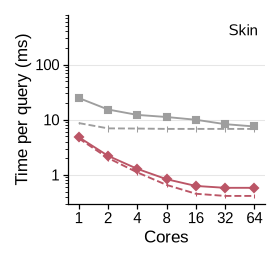

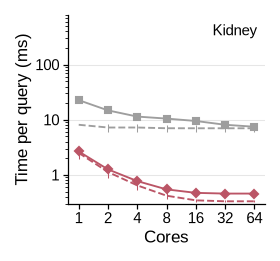

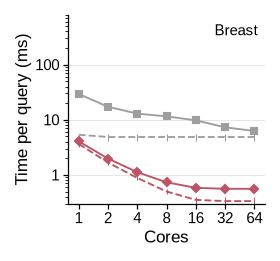

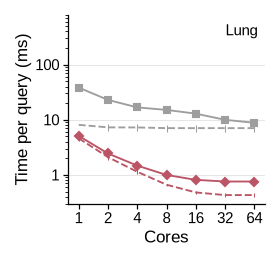

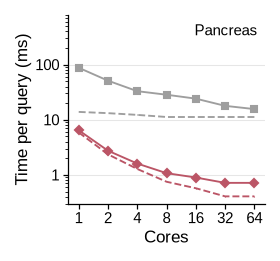

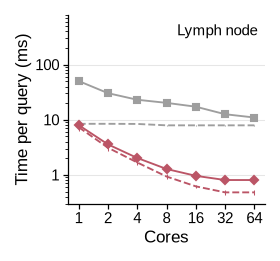

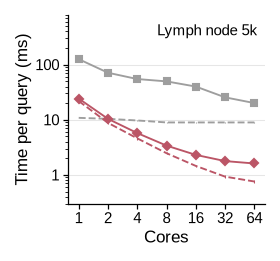

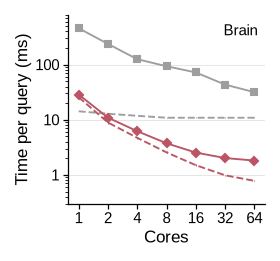

In [2]:
def panel(fig, k, first_col=True, last_row=True):
    ax = ps.axes(fig, left=LEFT, bottom=BOTTOM, right=RIGHT, top=TOP)
    d = S[k]
    for col, qcol, tier, mk, _ in METHODS:
        c = ps.TIER_COLORS[tier]
        ax.errorbar(d.threads, d[col], yerr=d[f"{col}_sd"], color=c, marker=mk, ms=2.8, mfc=c, mec=c, lw=0.9,
                    elinewidth=0.5, capsize=0, zorder=3)
        ax.errorbar(d.threads, d[qcol], yerr=d[f"{qcol}_sd"], color=c, ls="--", lw=0.9, elinewidth=0.5, capsize=0,
                    zorder=2)  # the query logarithms: the floor each end-to-end line approaches
    ax.set_xscale("log", base=2)
    ax.xaxis.set_major_locator(FixedLocator(CORES))
    ax.xaxis.set_major_formatter(lambda v, _p: f"{v:g}")
    ax.xaxis.set_minor_locator(NullLocator())
    ax.set_xlim(CORES[0] / 1.3, CORES[-1] * 1.3)
    ax.set_yscale("log")
    ps.plain_log(ax, "y", subs=(1.0,))
    ps.log_grid(ax, "y")
    ax.set_ylim(*YLIM)
    ax.text(0.96, 0.95, ps.DATASET_LABELS[k], transform=ax.transAxes, ha="right", va="top", fontsize=ps.TICK_PT)
    if first_col:
        ax.set_ylabel("Time per query (ms)")
    else:
        ax.set_yticklabels([])
    if last_row:
        ax.set_xlabel("Cores")


for k in KEYS:
    fig = ps.panel(W_P, H_P); panel(fig, k); ps.save_panel(fig, FIG, k)

## Legend and full figure

figures/figS8_parallel/panels/legend.pdf/.png: 180 x 7 mm, 0.0 / 0.1 MB
figures/figS8_parallel/figS8_parallel.pdf/.png: 180 x 91 mm, 0.0 / 1.0 MB


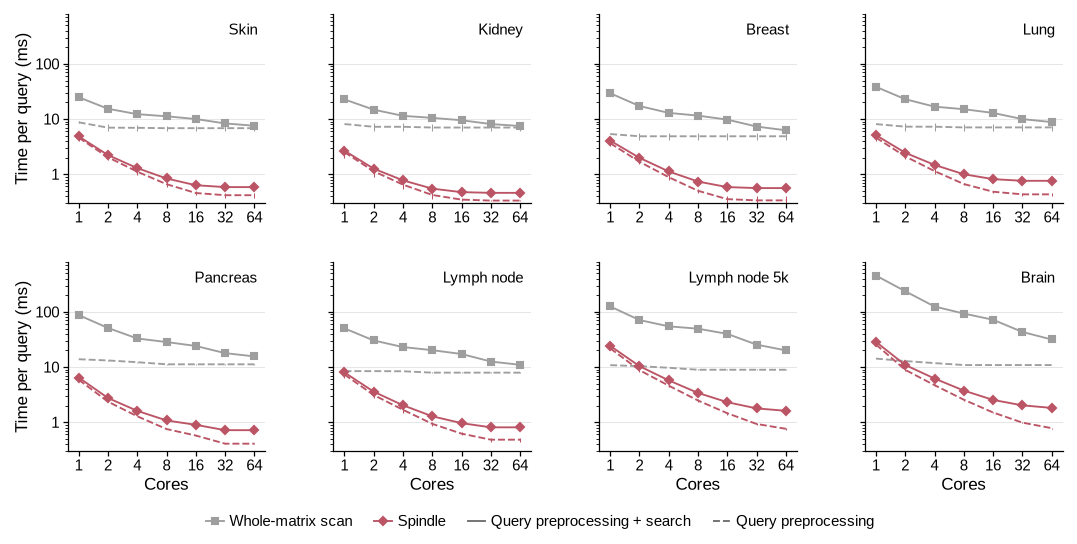

<Figure size 1062.99x41.3386 with 0 Axes>

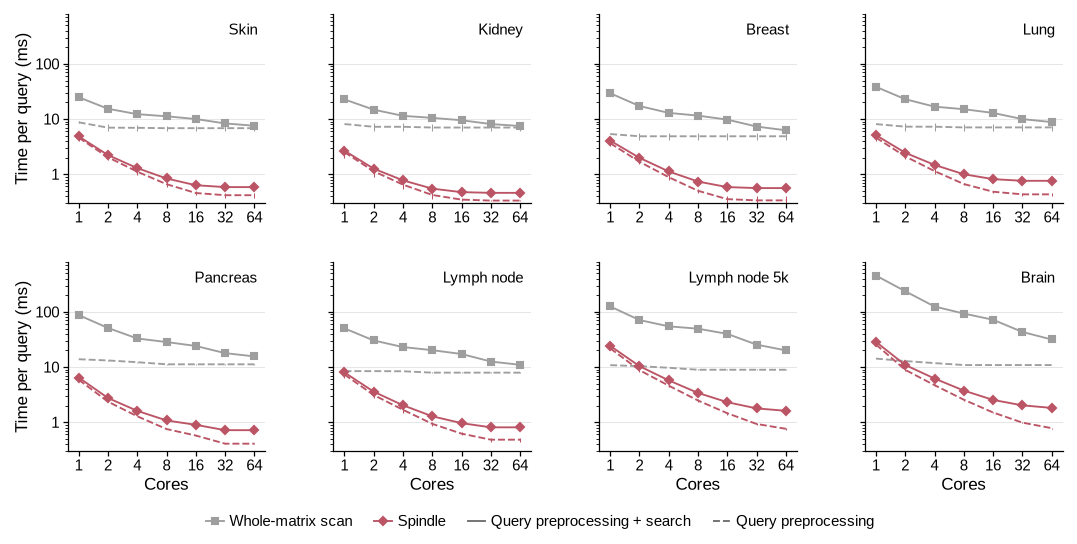

In [3]:
def legend(fig):
    handles = [Line2D([], [], color=ps.TIER_COLORS[t], marker=m, ms=3.0, lw=0.9, label=lab) for _, _, t, m, lab in METHODS]
    handles += [Line2D([], [], color=ps.MUTED, lw=0.9, label="Query preprocessing + search"),
                Line2D([], [], color=ps.MUTED, lw=0.9, ls="--", label="Query preprocessing")]
    fig.legend(handles=handles, ncol=4, loc="center", columnspacing=1.5)


fig = ps.panel(180, LEG_H); legend(fig); ps.save_panel(fig, FIG, "legend")

nrow = -(-len(KEYS) // NCOL)
page = ps.page(NCOL * W_P, nrow * H_P + LEG_H)
for i, k in enumerate(KEYS):
    r, c = divmod(i, NCOL)
    panel(ps.place(page, None, c * W_P, r * H_P, W_P, H_P), k, first_col=c == 0, last_row=r == nrow - 1)
legend(ps.place(page, None, 0, nrow * H_P, NCOL * W_P, LEG_H))
ps.save_figure(page, FIG)
page